# Prudential Life Insurance Assessment — Analyse exploratoire des données



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

## 1. Chargement et structure

In [39]:
# Adapter le chemin si besoin (Databricks : "/dbfs/FileStore/.../train.csv" par exemple)
chemin_fichier = r"C:\Users\koule\Documents\DOC3A\Applied stat learning\Projet\train.csv"
donnees = pd.read_csv(chemin_fichier)

print("Dimensions :", donnees.shape)
donnees.iloc[:5, :12]

Dimensions : (59381, 128)


,Id,Product_Info_1,Product_Info_2,Product_Info_3,Product_Info_4,Product_Info_5,Product_Info_6,Product_Info_7,Ins_Age,Ht,Wt,BMI
0,2,1,D3,10,0.076923,2,1,1,0.641791,0.581818,0.148536,0.323008
1,5,1,A1,26,0.076923,2,3,1,0.059701,0.600000,0.131799,0.272288
2,6,1,E1,26,0.076923,2,3,1,0.029851,0.745455,0.288703,0.428780
3,7,1,D4,10,0.487179,2,3,1,0.164179,0.672727,0.205021,0.352438
4,8,1,D2,26,0.230769,2,3,1,0.417910,0.654545,0.234310,0.424046


In [40]:
# Types pandas : attention, beaucoup de catégorielles sont codées en entiers
print(donnees.dtypes.value_counts())
print()
print("Id unique :", donnees["Id"].is_unique)
print("Mémoire (Mo) :", round(donnees.memory_usage(deep=True).sum() / 1e6, 1))

int64      109
float64     18
str          1
Name: count, dtype: int64

Id unique : True
Mémoire (Mo) : 60.9


## 2. Typologie des variables

On regroupe les colonnes selon la documentation  : continues, discrètes, binaires, catégorielles.

In [41]:
cols_continues = [
    "Product_Info_4", "Ins_Age", "Ht", "Wt", "BMI",
    "Employment_Info_1", "Employment_Info_4", "Employment_Info_6",
    "Insurance_History_5",
    "Family_Hist_2", "Family_Hist_3", "Family_Hist_4", "Family_Hist_5",
]
cols_discretes = [
    "Medical_History_1", "Medical_History_10", "Medical_History_15",
    "Medical_History_24", "Medical_History_32",
]
cols_binaires = [c for c in donnees.columns if c.startswith("Medical_Keyword")]

cols_categorielles = []
for nom_col in donnees.columns:
    if nom_col in ["Id", "Response"]:
        continue
    if nom_col in cols_continues or nom_col in cols_discretes or nom_col in cols_binaires:
        continue
    cols_categorielles.append(nom_col)

types_variables = {
    "continues": len(cols_continues),
    "discrètes": len(cols_discretes),
    "binaires (Medical_Keyword)": len(cols_binaires),
    "catégorielles": len(cols_categorielles),
}
print(types_variables, "-> total", sum(types_variables.values()), "variables explicatives")

{'continues': 13, 'discrètes': 5, 'binaires (Medical_Keyword)': 48, 'catégorielles': 60} -> total 126 variables explicatives


In [42]:
# Familles de variables (préfixe)
familles = {}
for nom_col in donnees.columns:
    if nom_col in ["Id", "Response"]:
        continue
    prefixe = nom_col.rsplit("_", 1)[0]
    familles[prefixe] = familles.get(prefixe, 0) + 1
pd.Series(familles, name="nb_variables").to_frame()

,nb_variables
Product_Info,7
Ins,1
Ht,1
Wt,1
BMI,1
Employment_Info,6
InsuredInfo,7
Insurance_History,8
Family_Hist,5
Medical_History,41


In [43]:
# Cardinalité des catégorielles : repérer les variables à très nombreuses modalités
cardinalite = donnees[cols_categorielles].nunique().sort_values(ascending=False)
print(cardinalite.head(8))

Medical_History_2      579
Employment_Info_2       36
Product_Info_3          34
Product_Info_2          19
InsuredInfo_3           11
InsuredInfo_1            3
Insurance_History_9      3
Product_Info_7           3
dtype: int64


`Medical_History_2` (~580 modalités), `Product_Info_3` ou `Employment_Info_2` ont une cardinalité élevée : leur encodage demandera de l'attention (regroupement des modalités rares, encodage cible avec validation croisée, etc.).

## 3. La cible `Response`

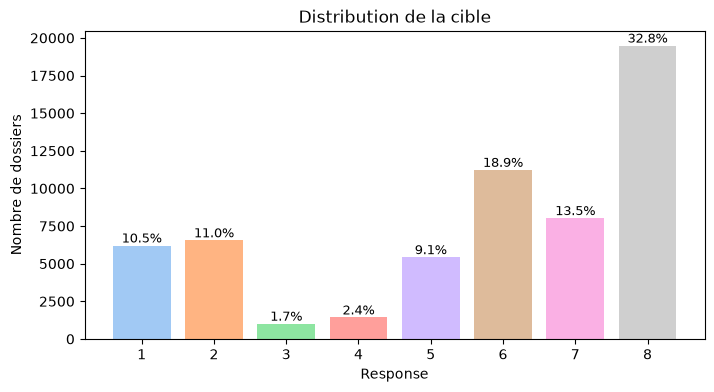

Médiane : 6.0
Ratio classe la plus fréquente / la plus rare : 19.2


In [44]:
effectifs = donnees["Response"].value_counts().sort_index()
frequences = (effectifs / len(donnees) * 100).round(1)

fig, axe = plt.subplots(figsize=(8, 4))
axe.bar(effectifs.index, effectifs.values, color=sns.color_palette("pastel"))
for niveau, freq in frequences.items():
    axe.text(niveau, effectifs[niveau], f"{freq}%", ha="center", va="bottom", fontsize=9)
axe.set_xlabel("Response")
axe.set_ylabel("Nombre de dossiers")
axe.set_title("Distribution de la cible")
plt.show()

print("Médiane :", donnees["Response"].median())
print("Ratio classe la plus fréquente / la plus rare :", round(effectifs.max() / effectifs.min(), 1))

- Cible **ordinale** à 8 niveaux, **déséquilibrée** : la classe 8 pèse ~1/3 des dossiers, les classes 3 et 4 ne représentent que ~2 % chacune.
- La **direction** de l'échelle n'est pas documentée. Les sections 6 et 8 montrent que `Response` **baisse** quand l'IMC augmente et quand le nombre de mots-clés médicaux augmente : le niveau 8 correspond donc plutôt aux profils les **moins** à risque (à confirmer, c'est une lecture empirique).
- Conséquence pour la modélisation : traiter la cible comme ordinale (régression + seuils optimisés pour le kappa pondéré quadratique) plutôt que comme une classification nominale.

## 4. Valeurs manquantes

13 variables avec des valeurs manquantes sur 126


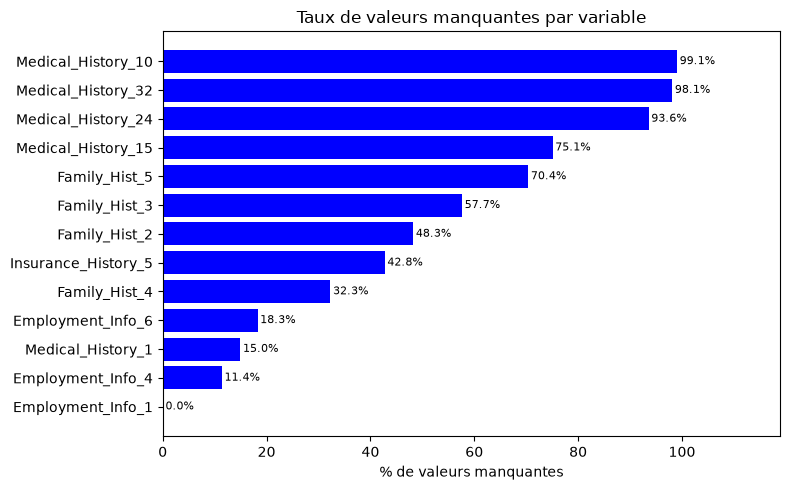

In [45]:
taux_manquants = donnees.isna().mean().sort_values(ascending=False)
taux_manquants = taux_manquants[taux_manquants > 0]
cols_avec_manquants = list(taux_manquants.index)

print(len(cols_avec_manquants), "variables avec des valeurs manquantes sur", donnees.shape[1] - 2)

fig, axe = plt.subplots(figsize=(8, 5))
valeurs_pct = taux_manquants.values[::-1] * 100
barres = axe.barh(taux_manquants.index[::-1], valeurs_pct, color="blue")

axe.set_xlabel("% de valeurs manquantes")
axe.set_title("Taux de valeurs manquantes par variable")

# Ajout des % au bout de chaque barre
for barre, valeur in zip(barres, valeurs_pct):
    axe.text(
        valeur + 0.5,
        barre.get_y() + barre.get_height() / 2,
        f"{valeur:.1f}%",
        va="center",
        ha="left",
        fontsize=8,
        color="black"
    )

# Légère marge pour ne pas couper les labels à droite
axe.set_xlim(0, max(valeurs_pct) * 1.2)
plt.tight_layout()
plt.show()

In [47]:
donnees["Medical_History_15"].value_counts(dropna=False).sort_index()

Medical_History_15
0.0       2135
1.0        237
2.0        132
3.0        109
4.0         74
         ...  
237.0       34
238.0       40
239.0       25
240.0     4566
NaN      44596
Name: count, Length: 242, dtype: int64

### 4.1 Le manque est-il informatif ?

On compare la `Response` entre les lignes où la variable est manquante et celles où elle est renseignée. Test de **Mann-Whitney** (adapté à une cible ordinale) ; avec ~59 000 lignes, la p-valeur est presque toujours minuscule : **c'est l'écart qui compte**, pas la p-valeur.

In [ ]:
resultats_manquants = []
for nom_col in cols_avec_manquants:
    est_manquant = donnees[nom_col].isna()
    reponse_manquant = donnees.loc[est_manquant, "Response"]
    reponse_renseigne = donnees.loc[~est_manquant, "Response"]
    p_valeur = mannwhitneyu(reponse_manquant, reponse_renseigne).pvalue
    resultats_manquants.append({
        "variable": nom_col,
        "taux_manquant_%": round(est_manquant.mean() * 100, 1),
        "nb_lignes_manquantes": int(est_manquant.sum()),
        "moyenne_si_manquant": round(reponse_manquant.mean(), 2),
        "moyenne_si_renseigne": round(reponse_renseigne.mean(), 2),
        "ecart": round(reponse_manquant.mean() - reponse_renseigne.mean(), 2),
        "p_valeur": f"{p_valeur:.1e}",
    })

tableau_manquants = pd.DataFrame(resultats_manquants)
tableau_manquants = tableau_manquants.sort_values("ecart", key=abs, ascending=False)
tableau_manquants.reset_index(drop=True)

,variable,taux_manquant_%,nb_lignes_manquantes,moyenne_si_manquant,moyenne_si_renseigne,ecart,p_valeur
0,Employment_Info_1,0.0,19,1.79,5.64,-3.85,2.3e-09
1,Medical_History_15,75.1,44596,5.95,4.70,1.24,0.0e+00
2,Medical_History_32,98.1,58274,5.66,4.52,1.14,3.7e-91
3,Medical_History_10,99.1,58824,5.65,4.62,1.03,1.4e-29
4,Family_Hist_4,32.3,19184,5.02,5.93,-0.92,0.0e+00
5,Family_Hist_5,70.4,41811,5.90,5.02,0.88,0.0e+00
6,Family_Hist_2,48.3,28656,5.19,6.05,-0.86,0.0e+00
7,Family_Hist_3,57.7,34241,5.95,5.21,0.75,0.0e+00
8,Medical_History_24,93.6,55580,5.67,5.09,0.59,4.2e-76
9,Medical_History_1,15.0,8889,5.94,5.58,0.36,2.5e-35


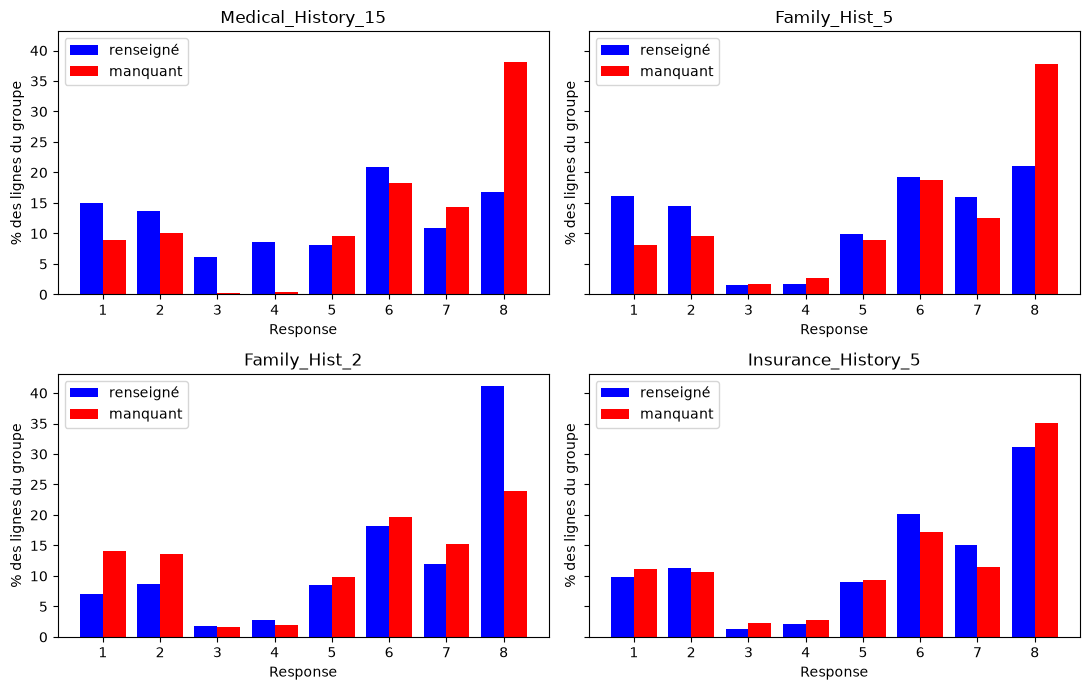

In [ ]:
# Distribution complète de Response (et non juste la moyenne) pour 4 variables
variables_a_voir = ["Medical_History_15", "Family_Hist_5", "Family_Hist_2", "Insurance_History_5"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for axe, nom_col in zip(axes.ravel(), variables_a_voir):
    est_manquant = donnees[nom_col].isna()
    repartition = pd.crosstab(est_manquant, donnees["Response"], normalize="index") * 100
    axe.bar(np.arange(1, 9) - 0.2, repartition.loc[False].values, width=0.4, color='blue', label="renseigné")
    axe.bar(np.arange(1, 9) + 0.2, repartition.loc[True].values, width=0.4, color='red', label="manquant")
    axe.set_title(nom_col)
    axe.set_xlabel("Response")
    axe.set_ylabel("% des lignes du groupe")
    axe.legend()
plt.tight_layout()
plt.show()

**Lecture**
- Manque associé à une `Response` **plus élevée** : `Medical_History_15`, `_32`, `_10`, `_24`, `_1` et `Family_Hist_5`, `Family_Hist_3` (écart de +0,4 à +1,2 point). Un historique médical « vide » correspond sans doute à un dossier simple.
- Manque associé à une `Response` **plus basse** : `Family_Hist_2` et `Family_Hist_4` (≈ -0,9 point).
- Aucun écart notable : `Insurance_History_5` et `Employment_Info_6` (écart ≈ -0,05, p-valeur non significative) → manque probablement non informatif.
- `Employment_Info_1` ressort en tête du tableau mais ne compte que **19 lignes manquantes** : écart non fiable, à ignorer.
- Pour `Medical_History_15`, les classes 3 et 4 disparaissent presque quand la variable est manquante (graphique).

→ **Garder des indicateurs de manque** (`est_manquant_X`) au lieu d'imputer silencieusement.

### 4.2 Les manques arrivent-ils par blocs ?

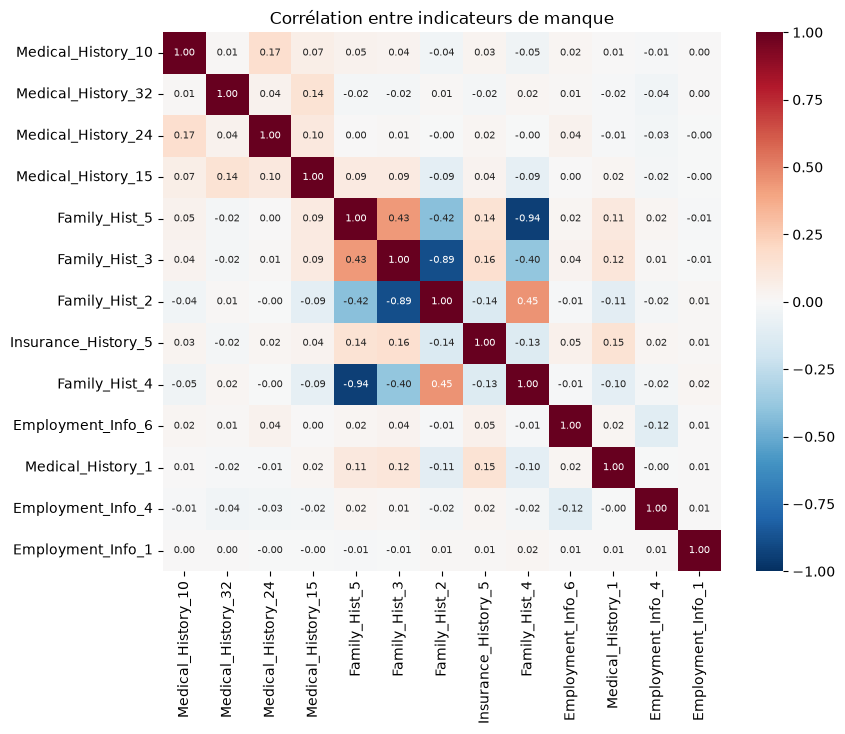

In [ ]:
indicateurs_manquants = donnees[cols_avec_manquants].isna().astype(int)
correlation_manquants = indicateurs_manquants.corr()

fig, axe = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation_manquants, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=axe)
axe.set_title("Corrélation entre indicateurs de manque")
plt.show()

In [ ]:
# Nombre de valeurs manquantes par ligne
donnees["nb_manquants"] = donnees[cols_avec_manquants].isna().sum(axis=1)
print(donnees["nb_manquants"].value_counts().sort_index().to_dict())
print("Spearman avec Response :", round(donnees["nb_manquants"].corr(donnees["Response"], method="spearman"), 3))

{2: 6, 3: 116, 4: 925, 5: 6521, 6: 20637, 7: 19699, 8: 8994, 9: 2103, 10: 338, 11: 40, 12: 2}
Spearman avec Response : 0.115


## 5. Analyse univariée

### 5.1 Variables continues

In [ ]:
print(donnees[cols_continues].describe().T.round(3))

                       count   mean    std  min    25%    50%    75%    max
Product_Info_4       59381.0  0.329  0.283  0.0  0.077  0.231  0.487  1.000
Ins_Age              59381.0  0.406  0.197  0.0  0.239  0.403  0.567  1.000
Ht                   59381.0  0.707  0.074  0.0  0.655  0.709  0.764  1.000
Wt                   59381.0  0.293  0.089  0.0  0.226  0.289  0.345  1.000
BMI                  59381.0  0.469  0.122  0.0  0.386  0.451  0.533  1.000
Employment_Info_1    59362.0  0.078  0.082  0.0  0.035  0.060  0.100  1.000
Employment_Info_4    52602.0  0.006  0.033  0.0  0.000  0.000  0.000  1.000
Employment_Info_6    48527.0  0.361  0.350  0.0  0.060  0.250  0.550  1.000
Insurance_History_5  33985.0  0.002  0.007  0.0  0.000  0.001  0.002  1.000
Family_Hist_2        30725.0  0.475  0.155  0.0  0.362  0.464  0.580  1.000
Family_Hist_3        25140.0  0.498  0.140  0.0  0.402  0.520  0.598  1.000
Family_Hist_4        40197.0  0.445  0.163  0.0  0.324  0.423  0.563  0.944
Family_Hist_

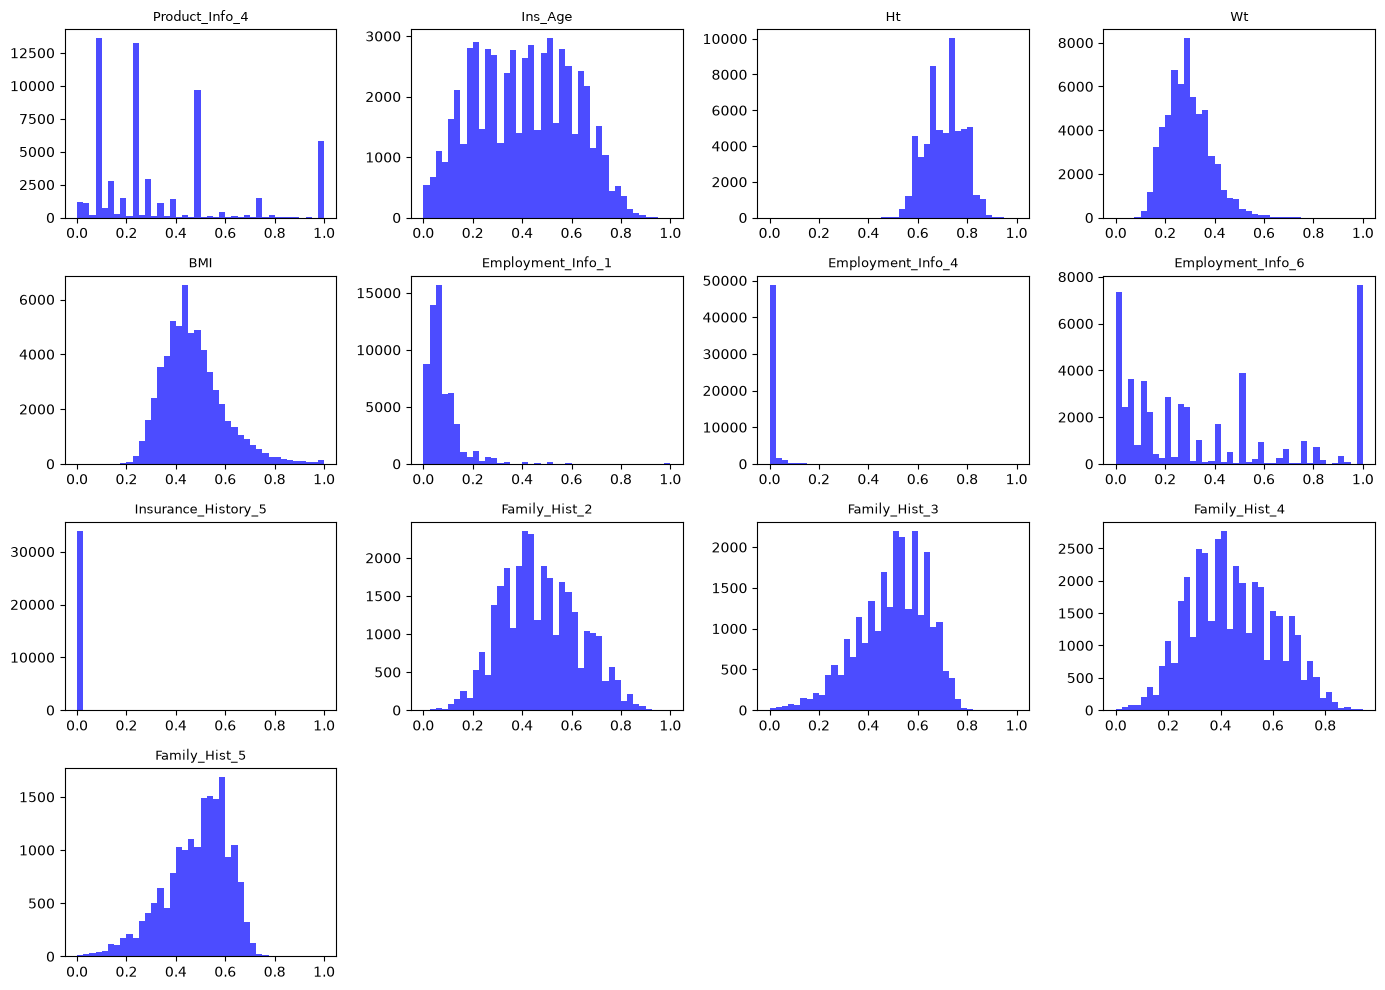

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(14, 10))
for axe, nom_col in zip(axes.ravel(), cols_continues):
    axe.hist(donnees[nom_col].dropna(), bins=40, color='blue', alpha=0.7)
    axe.set_title(nom_col, fontsize=9)
for axe in axes.ravel()[len(cols_continues):]:
    axe.axis("off")
plt.tight_layout()
plt.show()

Points à regarder :
- `Employment_Info_4` et `Insurance_History_5` ont presque toutes leurs valeurs collées à 0 avec quelques valeurs extrêmes (asymétrie forte, médiane ≈ 0) ;
- `Product_Info_4` est quasi discrète (pics marqués) ;
- `Wt`, `BMI` et `Employment_Info_1` sont asymétriques à droite (queue de valeurs élevées), `Ins_Age` est étalée sur toute la plage, `Ht` est étroite ;
- `Employment_Info_6` a deux pics aux extrêmes (0 et 1) ;
- les `Family_Hist_*` sont en cloche, avec des paliers (valeurs discrétisées) ;
- les valeurs sont normalisées : on ne peut pas lire l'âge, la taille ou le poids en unités réelles.

### 5.2 Variables catégorielles

In [ ]:
# Part des modalités rares (< 1 % des lignes) pour chaque catégorielle
resume_cat = []
for nom_col in cols_categorielles:
    frequences_modalites = donnees[nom_col].value_counts(normalize=True)
    resume_cat.append({
        "variable": nom_col,
        "nb_modalites": len(frequences_modalites),
        "part_modalite_dominante_%": round(frequences_modalites.iloc[0] * 100, 1),
        "nb_modalites_rares": int((frequences_modalites < 0.01).sum()),
    })
resume_cat = pd.DataFrame(resume_cat).sort_values("nb_modalites", ascending=False)
resume_cat.head(12).reset_index(drop=True)

,variable,nb_modalites,part_modalite_dominante_%,nb_modalites_rares
0,Medical_History_2,579,18.6,563
1,Employment_Info_2,36,58.2,31
2,Product_Info_3,34,85.7,31
3,Product_Info_2,19,24.1,6
4,InsuredInfo_3,11,31.6,3
5,InsuredInfo_1,3,79.5,1
6,Insurance_History_9,3,56.4,1
7,Product_Info_7,3,97.8,1
8,Insurance_History_4,3,46.9,0
9,Insurance_History_2,3,97.2,1


In [ ]:
# Variables presque constantes (modalité dominante > 95 %) : peu d'information
quasi_constantes = resume_cat[resume_cat["part_modalite_dominante_%"] > 95]["variable"].tolist()
print(len(quasi_constantes), "catégorielles dominées à plus de 95 % par une modalité :")
print(quasi_constantes)

21 catégorielles dominées à plus de 95 % par une modalité :
['Product_Info_7', 'Insurance_History_2', 'Medical_History_5', 'Medical_History_19', 'Medical_History_17', 'Medical_History_14', 'Medical_History_11', 'Medical_History_7', 'Medical_History_27', 'Medical_History_30', 'Medical_History_31', 'Medical_History_35', 'Medical_History_20', 'Medical_History_40', 'InsuredInfo_5', 'InsuredInfo_2', 'Product_Info_5', 'Product_Info_1', 'InsuredInfo_7', 'Medical_History_22', 'Medical_History_38']


### 5.3 Mots-clés médicaux (binaires)

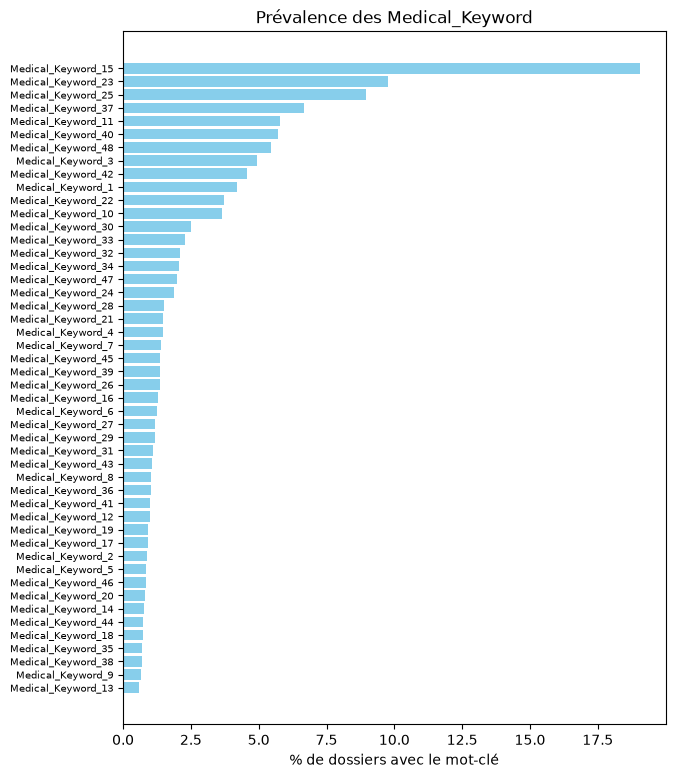

Mot-clé le plus fréquent : Medical_Keyword_15 19.0 %
Mots-clés présents dans moins de 1 % des dossiers : 13


In [ ]:
prevalence = donnees[cols_binaires].mean().sort_values(ascending=False)

fig, axe = plt.subplots(figsize=(7, 9))
axe.barh(prevalence.index[::-1], prevalence.values[::-1] * 100, color='skyblue')
axe.set_xlabel("% de dossiers avec le mot-clé")
axe.set_title("Prévalence des Medical_Keyword")
axe.tick_params(axis="y", labelsize=7)
plt.show()

print("Mot-clé le plus fréquent :", prevalence.index[0], round(prevalence.iloc[0] * 100, 1), "%")
print("Mots-clés présents dans moins de 1 % des dossiers :", int((prevalence < 0.01).sum()))

## 6. Relations avec la cible : variables continues

BMI                   -0.427
Wt                    -0.397
Ins_Age               -0.218
Ht                    -0.121
Family_Hist_4         -0.100
Family_Hist_2         -0.066
Employment_Info_4     -0.044
Family_Hist_5         -0.011
Family_Hist_3         -0.000
Employment_Info_6      0.024
Employment_Info_1      0.058
Insurance_History_5    0.145
Product_Info_4         0.249
dtype: float64


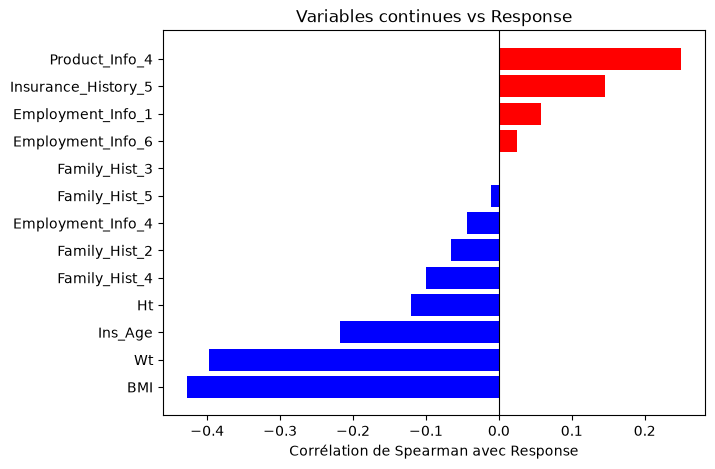

In [ ]:
# Corrélation de Spearman (adaptée à une cible ordinale), les manquants sont ignorés paire à paire
correlations = {}
for nom_col in cols_continues:
    correlations[nom_col] = donnees[nom_col].corr(donnees["Response"], method="spearman")

correlations = pd.Series(correlations).sort_values()
print(correlations.round(3))

fig, axe = plt.subplots(figsize=(7, 5))
couleurs = ['blue' if v < 0 else 'red' for v in correlations.values]
axe.barh(correlations.index, correlations.values, color=couleurs)
axe.axvline(0, color="black", linewidth=0.8)
axe.set_xlabel("Corrélation de Spearman avec Response")
axe.set_title("Variables continues vs Response")
plt.show()

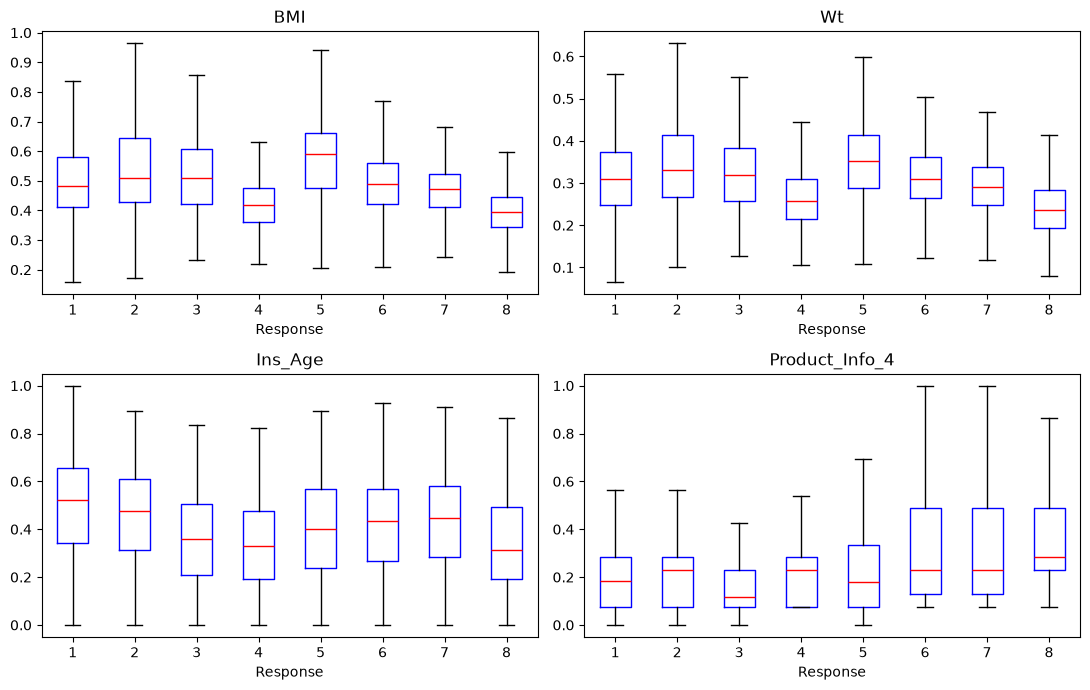

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for axe, nom_col in zip(axes.ravel(), ["BMI", "Wt", "Ins_Age", "Product_Info_4"]):
    valeurs_par_niveau = []
    for niveau in range(1, 9):
        valeurs_par_niveau.append(donnees.loc[donnees["Response"] == niveau, nom_col].dropna())
    axe.boxplot(valeurs_par_niveau, showfliers=False,
                boxprops={"color": 'blue'}, medianprops={"color": 'red'})
    axe.set_xticklabels(range(1, 9))
    axe.set_xlabel("Response")
    axe.set_title(nom_col)
plt.tight_layout()
plt.show()

`BMI` et `Wt` sont les plus liées à la cible (corrélation négative d'environ -0,4), puis `Ins_Age` (≈ -0,2) et `Product_Info_4` (≈ +0,25). Les relations sont **globalement monotones mais bruitées et non strictement ordonnées** : le niveau 5 présente par exemple l'IMC médian le plus élevé, et le niveau 4 un IMC bas. À explorer avec un modèle capable de non-linéarités (arbres, GAM).



## 7. Relations avec la cible : variables catégorielles

On utilise le **V de Cramér corrigé** (correction de biais de Bergsma). Le V classique est gonflé pour les variables à beaucoup de modalités comme `Medical_History_2`. Il traite `Response` comme **nominale** : il ignore l'ordre des niveaux.

In [ ]:
def v_cramer_corrige(serie_x, serie_y):
    tableau = pd.crosstab(serie_x, serie_y)
    n = tableau.values.sum()
    chi2 = chi2_contingency(tableau, correction=False)[0]
    phi2 = chi2 / n
    nb_lignes, nb_colonnes = tableau.shape
    phi2_corrige = max(0, phi2 - (nb_colonnes - 1) * (nb_lignes - 1) / (n - 1))
    lignes_corrigees = nb_lignes - (nb_lignes - 1) ** 2 / (n - 1)
    colonnes_corrigees = nb_colonnes - (nb_colonnes - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corrige / min(colonnes_corrigees - 1, lignes_corrigees - 1))

liens_categorielles = {}
for nom_col in cols_categorielles:
    liens_categorielles[nom_col] = v_cramer_corrige(donnees[nom_col], donnees["Response"])

liens_categorielles = pd.Series(liens_categorielles).sort_values(ascending=False)
print(liens_categorielles.head(15).round(3))

Medical_History_4     0.382
Medical_History_23    0.254
InsuredInfo_6         0.210
Medical_History_39    0.168
Medical_History_33    0.144
Product_Info_2        0.143
Employment_Info_3     0.141
Medical_History_6     0.121
InsuredInfo_5         0.106
Medical_History_16    0.105
InsuredInfo_7         0.104
Medical_History_40    0.104
Medical_History_30    0.100
Medical_History_13    0.097
InsuredInfo_2         0.092
dtype: float64


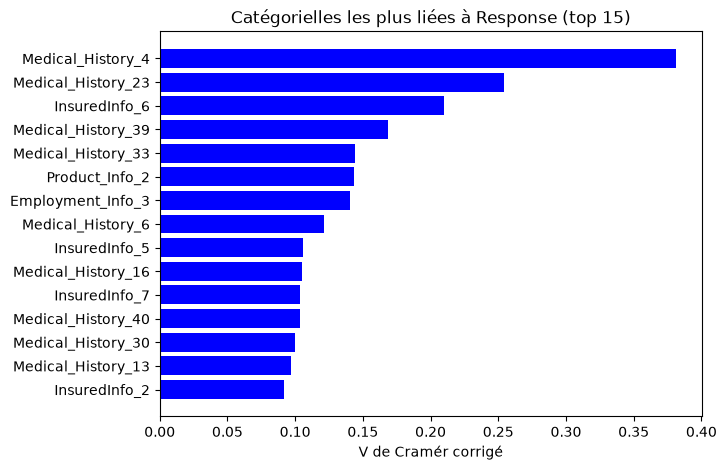

In [ ]:
top = liens_categorielles.head(15)
fig, axe = plt.subplots(figsize=(7, 5))
axe.barh(top.index[::-1], top.values[::-1], color='blue')
axe.set_xlabel("V de Cramér corrigé")
axe.set_title("Catégorielles les plus liées à Response (top 15)")
plt.show()

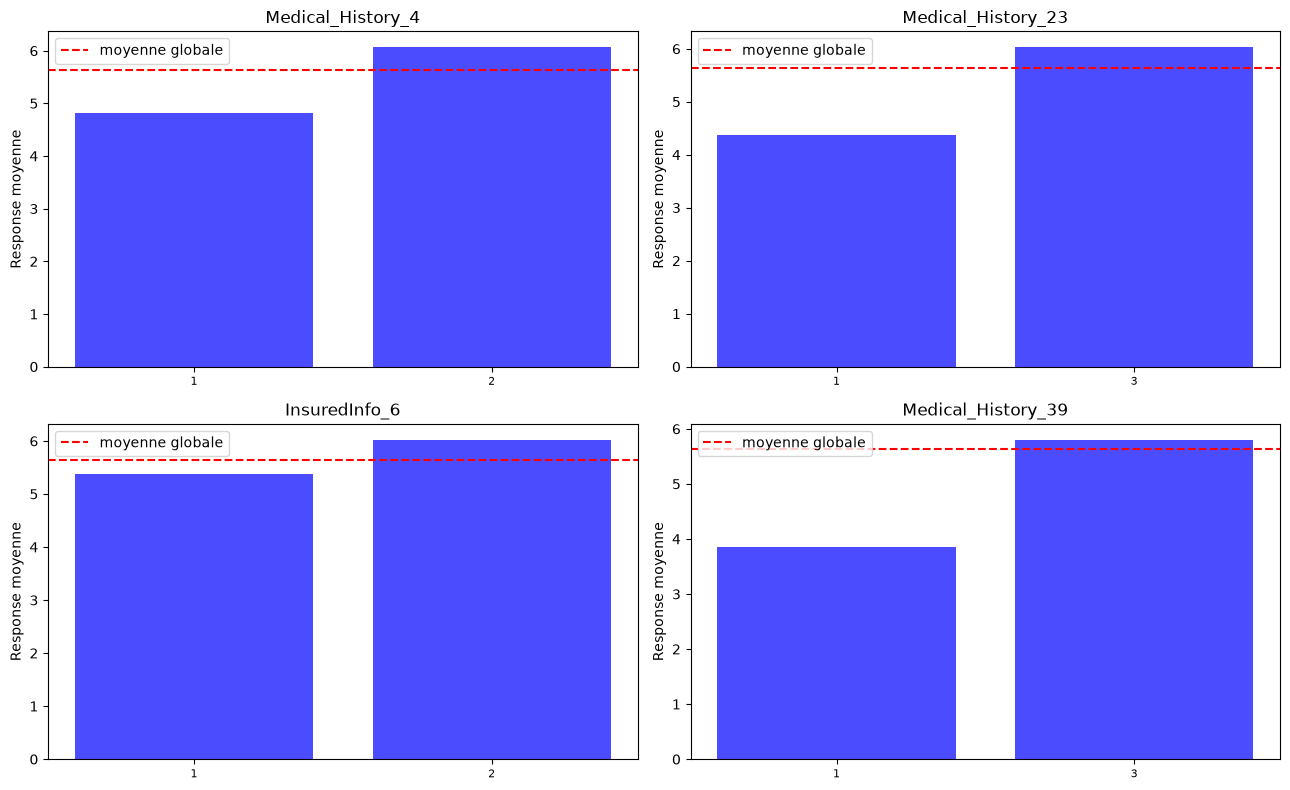

In [ ]:
# Response moyenne par modalité pour les 4 variables les plus liées (≤ 40 modalités)
variables_top = [c for c in liens_categorielles.index if donnees[c].nunique() <= 40][:4]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for axe, nom_col in zip(axes.ravel(), variables_top):
    resume = donnees.groupby(nom_col)["Response"].agg(["mean", "count"])
    resume = resume[resume["count"] >= 30]
    axe.bar(resume.index.astype(str), resume["mean"], color='blue', alpha=0.7)
    axe.axhline(donnees["Response"].mean(), color='red', linestyle="--", label="moyenne globale")
    axe.set_title(nom_col)
    axe.set_ylabel("Response moyenne")
    axe.tick_params(axis="x", labelsize=8, rotation=90 if len(resume) > 12 else 0)
    axe.legend()
plt.tight_layout()
plt.show()

**Lecture** : `Medical_History_4` est de loin la catégorielle la plus liée à la cible (V ≈ 0,38 : modalité 1 → `Response` moyenne 4,8 ; modalité 2 → 6,1), devant `Medical_History_23` (≈ 0,25) et `InsuredInfo_6` (≈ 0,21). `Medical_History_2`, malgré ses 579 modalités, ne ressort pas une fois la correction de biais appliquée.



### 7.1 Zoom sur `Product_Info_2` (lettre + chiffre)

In [ ]:
donnees["PI2_lettre"] = donnees["Product_Info_2"].str[0]
donnees["PI2_chiffre"] = donnees["Product_Info_2"].str[1].astype(int)

print(donnees.groupby("PI2_lettre")["Response"].agg(["mean", "count"]).round(2))
print()
print("V de Cramér Product_Info_2 complet :", round(v_cramer_corrige(donnees["Product_Info_2"], donnees["Response"]), 3))
print("V de Cramér lettre seule          :", round(v_cramer_corrige(donnees["PI2_lettre"], donnees["Response"]), 3))
print("V de Cramér chiffre seul          :", round(v_cramer_corrige(donnees["PI2_chiffre"], donnees["Response"]), 3))

            mean  count
PI2_lettre             
A           5.63  16615
B           6.45   1176
C           5.46    970
D           5.58  37973
E           6.14   2647

V de Cramér Product_Info_2 complet : 0.143
V de Cramér lettre seule          : 0.066
V de Cramér chiffre seul          : 0.128


La **lettre** seule porte peu d'information (V ≈ 0,07), le **chiffre** davantage (V ≈ 0,13) ; la variable complète reste la plus informative (≈ 0,14). Les lettres B et E ont une `Response` moyenne plus élevée (6,45 et 6,14).

## 8. Relations avec la cible : mots-clés médicaux

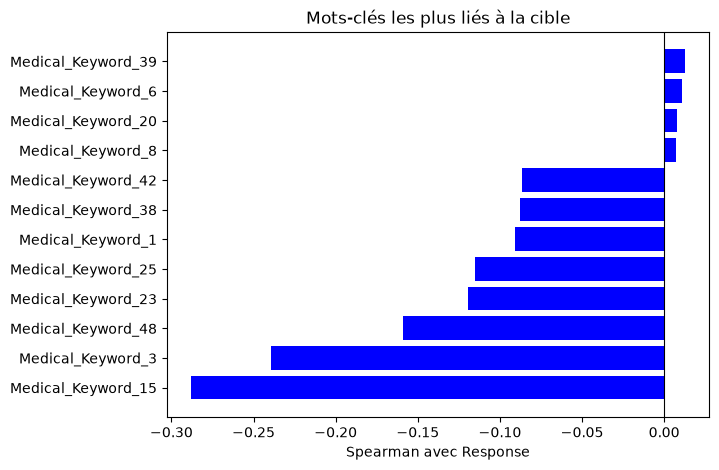

In [ ]:
# Corrélation de chaque mot-clé avec Response
correlations_mots = {}
for nom_col in cols_binaires:
    correlations_mots[nom_col] = donnees[nom_col].corr(donnees["Response"], method="spearman")
correlations_mots = pd.Series(correlations_mots).sort_values()

extremes = pd.concat([correlations_mots.head(8), correlations_mots.tail(4)])
fig, axe = plt.subplots(figsize=(7, 5))
axe.barh(extremes.index, extremes.values, color='blue')
axe.axvline(0, color="black", linewidth=0.8)
axe.set_xlabel("Spearman avec Response")
axe.set_title("Mots-clés les plus liés à la cible")
plt.show()

Spearman nb_mots_cles vs Response : -0.326
{1: 2.14, 2: 1.95, 3: 1.31, 4: 0.93, 5: 1.42, 6: 1.36, 7: 1.29, 8: 0.67}


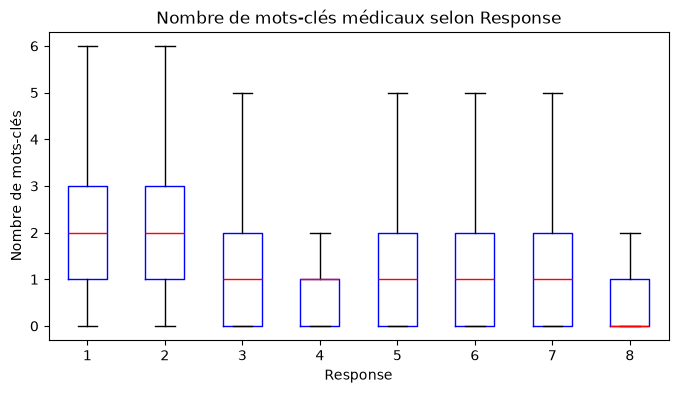

In [ ]:
# Variable agrégée : nombre de mots-clés médicaux présents
donnees["nb_mots_cles"] = donnees[cols_binaires].sum(axis=1)

print("Spearman nb_mots_cles vs Response :", round(donnees["nb_mots_cles"].corr(donnees["Response"], method="spearman"), 3))
print(donnees.groupby("Response")["nb_mots_cles"].mean().round(2).to_dict())

fig, axe = plt.subplots(figsize=(8, 4))
axe.boxplot([donnees.loc[donnees["Response"] == n, "nb_mots_cles"] for n in range(1, 9)],
            showfliers=False, boxprops={"color": 'blue'}, medianprops={"color": 'red'})
axe.set_xticklabels(range(1, 9))
axe.set_xlabel("Response")
axe.set_ylabel("Nombre de mots-clés")
axe.set_title("Nombre de mots-clés médicaux selon Response")
plt.show()

Le **nombre de mots-clés** (somme des 48 binaires) est plus lié à la cible que la plupart des mots-clés pris isolément : c'est une feature d'agrégation simple et efficace. La tendance est nette (corrélation ≈ -0,33 : environ 2 mots-clés en moyenne au niveau 1, 0,7 au niveau 8) mais **pas strictement monotone** entre niveaux voisins (le niveau 4 est plus bas que le 5). Cohérent avec l'idée que 8 = profil le moins à risque.

## 9. Analyse multivariée et redondances

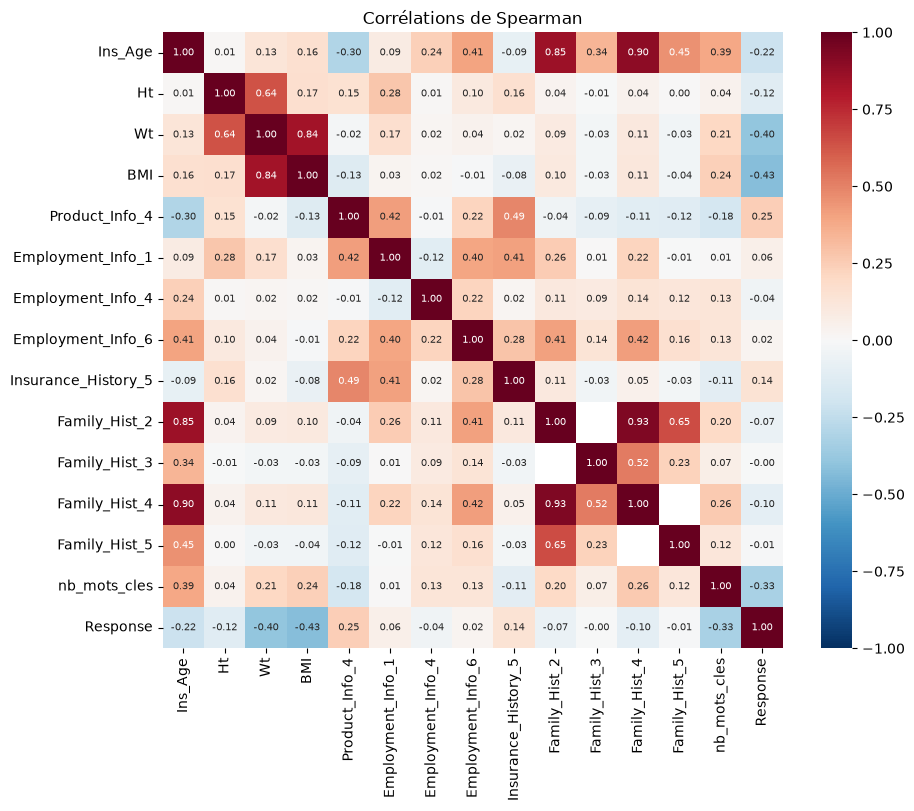

In [ ]:
variables_corr = ["Ins_Age", "Ht", "Wt", "BMI", "Product_Info_4", "Employment_Info_1",
                  "Employment_Info_4", "Employment_Info_6", "Insurance_History_5",
                  "Family_Hist_2", "Family_Hist_3", "Family_Hist_4", "Family_Hist_5",
                  "nb_mots_cles", "Response"]
matrice = donnees[variables_corr].corr(method="spearman")

fig, axe = plt.subplots(figsize=(10, 8))
sns.heatmap(matrice, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, ax=axe)
axe.set_title("Corrélations de Spearman")
plt.show()

       Wt    Ht   BMI
Wt   1.00  0.64  0.84
Ht   0.64  1.00  0.17
BMI  0.84  0.17  1.00


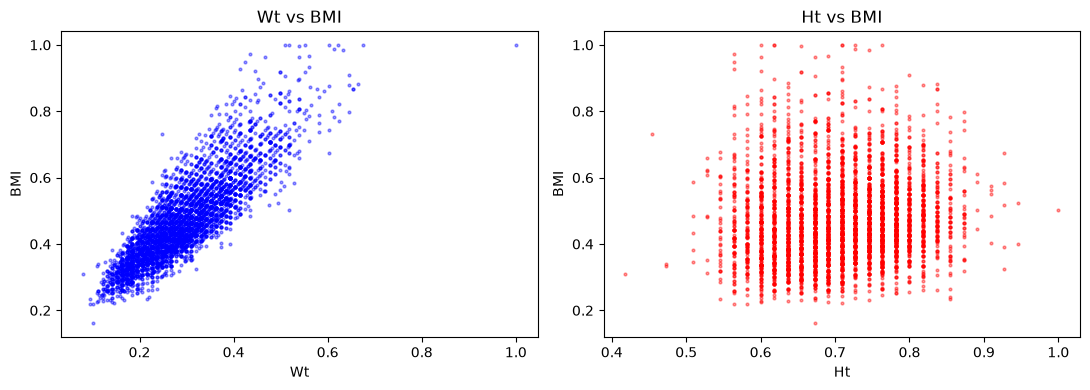

In [ ]:
# BMI ≈ Wt / Ht² : redondance structurelle
print(donnees[["Wt", "Ht", "BMI"]].corr(method="spearman").round(2))

echantillon = donnees.sample(5000, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(echantillon["Wt"], echantillon["BMI"], s=4, alpha=0.4, color='blue')
axes[0].set_xlabel("Wt"); axes[0].set_ylabel("BMI"); axes[0].set_title("Wt vs BMI")
axes[1].scatter(echantillon["Ht"], echantillon["BMI"], s=4, alpha=0.4, color='red')
axes[1].set_xlabel("Ht"); axes[1].set_ylabel("BMI"); axes[1].set_title("Ht vs BMI")
plt.tight_layout()
plt.show()

`BMI` est très corrélé à `Wt` (≈ 0,84) et peu à `Ht` : à surveiller pour les modèles linéaires (colinéarité), sans gravité pour les arbres. Les `Family_Hist_*` sont corrélées entre elles (et leurs manques aussi, cf. 4.2).

## 10. Cohérence et qualité des données

In [ ]:
# 1. Les continues sont-elles bien dans [0, 1] ?
for nom_col in cols_continues:
    minimum = donnees[nom_col].min()
    maximum = donnees[nom_col].max()
    if minimum < 0 or maximum > 1:
        print("Hors [0, 1] :", nom_col, minimum, maximum)
print("Contrôle des bornes terminé.")

# 2. Binaires : seulement 0 et 1 ?
valeurs_binaires = set(np.unique(donnees[cols_binaires].values))
print("Valeurs des Medical_Keyword :", valeurs_binaires)

# 3. Doublons (hors Id)
cols_sans_id = [c for c in donnees.columns if c not in ["Id", "Response", "nb_manquants",
                                                        "PI2_lettre", "PI2_chiffre", "nb_mots_cles"]]
nb_doublons = donnees.duplicated(subset=cols_sans_id).sum()
print("Lignes dupliquées (variables explicatives identiques) :", nb_doublons)

Contrôle des bornes terminé.
Valeurs des Medical_Keyword : {np.int64(0), np.int64(1)}
Lignes dupliquées (variables explicatives identiques) : 30


In [ ]:
# Les doublons ont-ils la même Response ?
masque = donnees.duplicated(subset=cols_sans_id, keep=False)
doublons = donnees[masque]
nb_reponses_distinctes = doublons.groupby(cols_sans_id, dropna=False)["Response"].nunique()
print("Groupes de doublons :", len(nb_reponses_distinctes))
print("Groupes avec Response différentes :", int((nb_reponses_distinctes > 1).sum()))

Groupes de doublons : 28
Groupes avec Response différentes : 0


30 dossiers ont des variables explicatives strictement identiques à un autre (28 groupes) et, dans tous les cas, la **même** `Response` : pas de contradiction, mais à surveiller en validation croisée (fuite possible entre train et validation si les doublons sont séparés). 

## 11. Pistes de feature engineering (test rapide)

On teste le lien (Spearman) de quelques features simples avec la cible, à comparer avec les variables brutes.

In [ ]:
donnees["manquant_MH15"] = donnees["Medical_History_15"].isna().astype(int)
donnees["manquant_FH5"] = donnees["Family_Hist_5"].isna().astype(int)
donnees["manquant_FH2"] = donnees["Family_Hist_2"].isna().astype(int)
donnees["bmi_x_age"] = donnees["BMI"] * donnees["Ins_Age"]

# Lettre de Product_Info_2 encodée par sa Response moyenne (à refaire en validation croisée en vrai !)
moyenne_par_lettre = donnees.groupby("PI2_lettre")["Response"].mean()
donnees["PI2_lettre_cible"] = donnees["PI2_lettre"].map(moyenne_par_lettre)

features_testees = ["BMI", "nb_mots_cles", "nb_manquants", "manquant_MH15", "manquant_FH5",
                    "manquant_FH2", "bmi_x_age", "PI2_chiffre", "PI2_lettre_cible"]
resultats = {}
for nom_col in features_testees:
    resultats[nom_col] = round(donnees[nom_col].corr(donnees["Response"], method="spearman"), 3)
pd.Series(resultats, name="Spearman").sort_values(key=abs, ascending=False).to_frame()

,Spearman
BMI,-0.427
bmi_x_age,-0.353
nb_mots_cles,-0.326
manquant_MH15,0.233
manquant_FH2,-0.184
manquant_FH5,0.169
nb_manquants,0.115
PI2_chiffre,0.071
PI2_lettre_cible,0.044


 **Piège** : l'encodage de `PI2_lettre_cible` ci-dessus utilise la cible sur tout le jeu de données : c'est une **fuite** si on l'utilise tel quel pour évaluer un modèle. À calculer à l'intérieur de chaque pli de validation croisée.

## 12. Synthèse et prochaines étapes

**Ce que l'on retient**

| Thème | Constat | Conséquence pour la modélisation |
|---|---|---|
| Cible | Ordinale, 8 niveaux, classe 8 ≈ 33 %, classes 3 et 4 ≈ 2 % | Régression + seuils optimisés pour le kappa pondéré quadratique ; stratifier les plis |
| Sens de l'échelle | `Response` baisse quand l'IMC et le nombre de mots-clés augmentent | Lecture empirique : 8 ≈ profil le moins à risque |
| Manquants | 13 variables concernées, 5 à plus de 70 % ; le manque est **informatif** (`Medical_History_15`, `Family_Hist_2/4/5`…) | Créer des indicateurs de manque, ne pas supprimer les colonnes très vides |
| Signaux forts (continues) | `BMI` (-0,43), `Wt` (-0,40), `Product_Info_4` (+0,25), `Ins_Age` (-0,22) | Relations monotones mais bruitées : privilégier les arbres / GBM |
| Signaux forts (catégorielles) | `Medical_History_4` (V = 0,38), `Medical_History_23`, `InsuredInfo_6`, `Medical_History_39` | À conserver ; plusieurs sont binaires/ternaires |
| Mots-clés médicaux | Le **nombre** de mots-clés (-0,33) résume mieux que chaque mot-clé isolé | Ajouter `nb_mots_cles` |
| Redondance | `BMI` ≈ f(`Wt`, `Ht`) (ρ = 0,84 avec `Wt`) ; 21 catégorielles quasi constantes (> 95 % d'une modalité) | Surveiller la colinéarité (modèles linéaires) ; filtrer ou regrouper les quasi-constantes |
| Cardinalité | `Medical_History_2` (579 modalités), `Employment_Info_2`, `Product_Info_3` | Regrouper les modalités rares, encodage cible **dans** la validation croisée |
| Qualité | Bornes [0, 1] respectées, 30 lignes dupliquées (même `Response`) | Pas de nettoyage lourd ; attention aux doublons entre plis |

**Pistes de features** : `nb_mots_cles`, `nb_manquants`, indicateurs de manque (`Medical_History_15`, `Family_Hist_2/5`), lettre et chiffre de `Product_Info_2`, interactions autour du BMI (`BMI × Ins_Age`).

**Prochaines étapes** : baseline (régression + seuils QWK, puis LightGBM/XGBoost), validation croisée stratifiée, comparaison train/test si `test.csv` est disponible.